In [ ]:
#pip install langchain_chroma

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [21]:
from dotenv import load_dotenv
from langchain_core.prompts import ChatPromptTemplate
#from langchain_community.document_loaders import PyPDFLoader
from pypdf import PdfReader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import ChatOpenAI,OpenAIEmbeddings
from langchain_chroma import Chroma
#from langchain_community.vectorstores import Chroma
from langchain_core.documents import Document


from langgraph.graph import StateGraph, START, END, MessagesState
from langchain_core.output_parsers import StrOutputParser
load_dotenv()

True

In [22]:
# step 1 :
pdf_reader = PdfReader("./documents/evs_oil_price_shock.pdf")

text = ""
for page in pdf_reader.pages:
    text += page.extract_text() + "\n"

print(text[:500])


# step 2 split documents into chunks
text_splitter = RecursiveCharacterTextSplitter(chunk_size=900, chunk_overlap=100)
docs = [Document(page_content=text)]

chunks = text_splitter.split_documents(docs)

print(len(chunks))

Will EVs Dampen the Oil Price
 Shock?
Electric Vehicles, Oil Demand Destruction, and the Future of Energy Price
 Volatility
 Version 1.0   |   April 2026
 Technical Reference Document

Will EVs Dampen the Oil Price Shock?
Version 1.0
Research Report — For Educational and RAG Pipeline Use
Page 2
Table of Contents
3
Executive Summary
 4
1. Introduction
  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  . 4
1.1 Scope and Methodology
 5
2. Oil 
51


In [23]:

print(len(chunks))

51


In [24]:
# lets intilize our embedding model
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")

# step 3.1 : intilize your storage system 
vectorstore = Chroma(
    collection_name="rag_base",
    embedding_function=embeddings,
)


# step 3.2 : add documents to your storage system. (chunk --> vectors)

vectorstore.add_documents(chunks)

['ebc93399-3501-4de4-a486-acfce51076d9',
 '8d0455c7-f085-4547-a40f-e6e038ecc946',
 '9703687a-ea53-4265-b0f5-e581cdbf314b',
 '8a737cc5-a3aa-49db-893a-790ae0971ae0',
 '34803a33-bc36-4c71-9722-5b60a6b09eef',
 'f3069714-3ee0-4f2f-ac7c-e04c76ec9287',
 'eb0db565-2fd5-4f0f-a01f-468f27336d00',
 'a85b7d20-01f3-4a21-9d98-87526028bb5f',
 'e2f7efc0-2ba9-40fb-83ca-2884f352c25d',
 '6529935a-f836-4689-827f-02a3cbfe8217',
 '6b23a19b-71d6-4388-968c-5f7e6bfed44e',
 'da63703e-51ce-4ba4-a34e-4253fc525743',
 '8d8fe397-aa56-4792-adbf-9bdfa85ebfa5',
 '5af44245-7bf2-4f0c-9eb0-c0750b1a2b41',
 '550ac3d2-afd7-4c7a-8bd9-12c74196ddbd',
 'eebb9ac3-c165-49c2-bda4-1985b0327a50',
 'b112b76f-4027-4a0d-85a7-d63bd4b8a4e7',
 '92f73cbd-cd96-498c-a86a-619fd7781b1b',
 '14ad1edd-fef5-45a0-9c46-acc643436649',
 'bad38013-d242-4882-9342-cde9ce94d76e',
 '0e56c761-0d63-4aac-a201-0bcd83630e26',
 'e65122e6-7528-4b22-9d90-a767db6305fd',
 'f658e985-ec19-4236-b4be-ae7584309805',
 '0e1dd73f-7128-4403-b8a4-41b88a7432c5',
 '70d69fa9-424c-

In [25]:
# step 4 : retrieval

retriever = vectorstore.as_retriever( search_kwargs={"k": 2})

In [26]:
# below is a sequential agentic rag using langgraph
# step 1 : Define your state
class AgenticRAGState(MessagesState):
    query: str
    retrieved_docs: list[Document]
    context: str
    generation: str


llm = ChatOpenAI(model="gpt-5-mini")

In [27]:
# step 2 : lets define the node
def retrieve(state: AgenticRAGState):
    docs = retriever.invoke(state['query'])
    context = "\n\n".join([doc.page_content for doc in docs])
    return {"retrieved_docs": docs, "context": context} 



def generate(state: AgenticRAGState):
    query = state['query']
    context = state['context']
    prompt_template = ChatPromptTemplate.from_messages([
        ("system", "Answer the question using only the context below.\n\nContext:\n{context}"),
        ("human", query)
    ])
    chain = prompt_template | llm | StrOutputParser()

    response = chain.invoke({"context": context, "query": query})
    return {"generation": response}

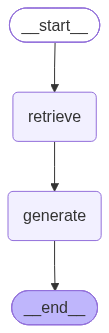

In [28]:
graph_builder = StateGraph(AgenticRAGState)

graph_builder.add_node("retrieve", retrieve)
graph_builder.add_node("generate", generate)

# now we will connect them using edges
graph_builder.add_edge(START, "retrieve")
graph_builder.add_edge("retrieve", "generate")
graph_builder.add_edge("generate", END)

graph = graph_builder.compile()

graph

In [29]:
test_query = "How will EVS impact oil demand in the next decade?"
result = graph.invoke({"query": test_query,"messages": []})

In [30]:
result

{'messages': [],
 'query': 'How will EVS impact oil demand in the next decade?',
 'retrieved_docs': [Document(id='d24eaf50-2aec-4bc7-a8e3-6a3761e519fa', metadata={}, page_content='Energy Agency, and McKinsey collectively project that EVs will account for between 40 and\n60 percent of new vehicle sales globally by 2030. The stock of EVs on the road — which\nmatters more than annual sales for oil displacement — is projected to grow from roughly 40\nmillion vehicles today to between 300 and 500 million by the early 2030s. Whether this is\nsufficient to materially alter the oil price formation process is the central question this report\naddresses.\n1.1 Scope and Methodology\n This report focuses on the relationship between passenger and light commercial vehicle\nelectrification and global oil demand dynamics. Heavy trucking, aviation, shipping, and\npetrochemical feedstock demand — which collectively account for roughly 43 percent of oil\nconsumption — are not the primary subject of analy

In [31]:
print(result['generation'])

Short answer
- EV adoption is projected to rise sharply over the next decade and will materially reduce oil use in passenger and light‑commercial vehicles, but whether that reduction is large enough to change global oil‑price formation is uncertain.

Key points from the report
- By 2030, major forecasters project EVs will make up roughly 40–60% of new vehicle sales globally.
- The stock of EVs — which matters more for oil displacement than annual sales — is projected to grow from about 40 million today to roughly 300–500 million by the early 2030s.
- The report focuses on passenger and light commercial vehicle electrification and its effect on oil demand; heavy trucking, aviation, shipping and petrochemical feedstock demand (together about 43% of oil consumption) are not the primary subject.

Implications for oil demand over the next decade
- Because the EV stock is expected to expand rapidly, oil consumption by passenger and light commercial vehicles should fall significantly as that 

In [32]:
test_query = "who is PM of india"
result = graph.invoke({"query": test_query,"messages": []})

In [33]:
result

{'messages': [],
 'query': 'who is PM of india',
 'retrieved_docs': [Document(id='09a76c58-af5c-45df-b407-c59dd4913635', metadata={}, page_content='manage the elevated transition-period vulnerability. The world with 500 million EVs will be\nmeaningfully less exposed to the oil price shocks that have periodically destabilized\neconomies for the past five decades, but it will not be immune to them.'),
  Document(id='4d3367a0-8795-4fb0-b348-cf413ea8ab43', metadata={}, page_content='manage the elevated transition-period vulnerability. The world with 500 million EVs will be\nmeaningfully less exposed to the oil price shocks that have periodically destabilized\neconomies for the past five decades, but it will not be immune to them.')],
 'context': 'manage the elevated transition-period vulnerability. The world with 500 million EVs will be\nmeaningfully less exposed to the oil price shocks that have periodically destabilized\neconomies for the past five decades, but it will not be immune to t

In [34]:
print(result['generation'])

The provided context does not contain any information about who the Prime Minister of India is, so I can’t answer that from the text you gave.
